### Importing Necessaries

In [1]:
import os
import math
import re
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.experimental import enable_iterative_imputer

#for preprocessing and Feature engineering
from sklearn.impute import (
    SimpleImputer,
    KNNImputer
)

from sklearn.feature_selection import (
    SelectKBest,
    SelectPercentile,
    RFE,
    RFECV,
    VarianceThreshold
)

from sklearn.preprocessing import (
    OneHotEncoder,
    MinMaxScaler,
    StandardScaler,
    RobustScaler,
    Normalizer,
    PolynomialFeatures,
    OrdinalEncoder,
    LabelEncoder,
    KBinsDiscretizer,
    FunctionTransformer
)

#Model Selection and Evaluation

from sklearn.model_selection import (
    train_test_split,
    cross_val_predict,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold,
    KFold,
    cross_validate
)

from sklearn.metrics import (
    accuracy_score,
    precision_recall_curve,
    roc_auc_score,
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    root_mean_squared_error,
    confusion_matrix,
    r2_score,
    classification_report,
    f1_score,
    recall_score,
    explained_variance_score,
    precision_score
)

#fro regression
from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso,
    ElasticNet,
    BayesianRidge,
    SGDRegressor,
    PassiveAggressiveRegressor
)

from sklearn.tree import(
    DecisionTreeRegressor
)

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    AdaBoostRegressor,
    ExtraTreesRegressor,
    BaggingRegressor
)

from sklearn.svm import (
    SVR,
    LinearSVR
)

from sklearn.neighbors import(
    KNeighborsRegressor
)

from sklearn.neural_network import(
    MLPRegressor,
    _multilayer_perceptron
)

#for Classification
from sklearn.linear_model import(
    LogisticRegression,
    RidgeClassifier,
    Perceptron,
    PassiveAggressiveClassifier,
    SGDClassifier
)

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import(
    RandomForestClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    ExtraTreesClassifier,
    BaggingClassifier
)

from sklearn.svm import (
    SVC,
    LinearSVC,
    NuSVC
)

from sklearn.neighbors import KNeighborsClassifier

from sklearn.naive_bayes import (
    GaussianNB,
    MultinomialNB,
    BernoulliNB,
    CategoricalNB,
    ComplementNB
)

from sklearn.neural_network import MLPClassifier

from sklearn.discriminant_analysis import(
    QuadraticDiscriminantAnalysis,
    LinearDiscriminantAnalysis
)

from sklearn.impute import IterativeImputer

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

import scipy.stats as stas

from scipy.stats import (
    anderson,
    jarque_bera,
    shapiro,
    normaltest,
    kstest
)

from statsmodels.stats.diagnostic import lilliefors

from scipy.stats import zscore

from sklearn.feature_extraction import FeatureHasher

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.feature_selection import SelectFromModel
from sklearn.base import BaseEstimator, TransformerMixin

### Loading Datasets

In [2]:
path = os.path.join('..','data', 'raw', 'used_cars.csv')
print(path)

..\data\raw\used_cars.csv


In [3]:
df=pd.read_csv(path)

#### Basic Initial Inspection 

In [4]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
df.head(1)

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capability,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"


In [5]:
df.tail(1)

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
4008,BMW,X3 xDrive30i,2020,"43,000 mi.",Gasoline,248.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,A/T,Gray,Brown,At least 1 accident or damage reported,Yes,"$40,000"


In [6]:
df.sample()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
69,Audi,A5 2.0T Premium Plus,2019,"47,523 mi.",Gasoline,248.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,Black,Black,None reported,Yes,"$31,000"


In [7]:
df.describe()

,model_year
count,4009.000000
mean,2015.515590
std,6.104816
min,1974.000000
25%,2012.000000
50%,2017.000000
75%,2020.000000
max,2024.000000


In [8]:
df.describe(include='all')

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
count,4009,4009,4009.000000,4009,3839,4009,4009,4009,4009,3896,3413,4009
unique,57,1898,NaN,2818,7,1146,62,319,156,2,1,1569
top,Ford,M3 Base,NaN,"110,000 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,A/T,Black,Black,None reported,Yes,"$15,000"
freq,386,30,NaN,16,3309,52,1037,905,2025,2910,3413,39
mean,NaN,NaN,2015.515590,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,6.104816,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,1974.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,2012.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,2017.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,2020.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
print(f"The memory consumed in memory is {(df.memory_usage(deep=True)/(1024*1024)).sum():.3f}MB")

The memory consumed in memory is 0.872MB


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   brand         4009 non-null   str  
 1   model         4009 non-null   str  
 2   model_year    4009 non-null   int64
 3   milage        4009 non-null   str  
 4   fuel_type     3839 non-null   str  
 5   engine        4009 non-null   str  
 6   transmission  4009 non-null   str  
 7   ext_col       4009 non-null   str  
 8   int_col       4009 non-null   str  
 9   accident      3896 non-null   str  
 10  clean_title   3413 non-null   str  
 11  price         4009 non-null   str  
dtypes: int64(1), str(11)
memory usage: 892.6 KB


In [11]:
df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capability,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric Hybrid,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


In [12]:
df['milage'] = (
    df['milage']
    .str.replace(',','')
    .str.replace('mi.','')
    .astype(float)
)

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   brand         4009 non-null   str    
 1   model         4009 non-null   str    
 2   model_year    4009 non-null   int64  
 3   milage        4009 non-null   float64
 4   fuel_type     3839 non-null   str    
 5   engine        4009 non-null   str    
 6   transmission  4009 non-null   str    
 7   ext_col       4009 non-null   str    
 8   int_col       4009 non-null   str    
 9   accident      3896 non-null   str    
 10  clean_title   3413 non-null   str    
 11  price         4009 non-null   str    
dtypes: float64(1), int64(1), str(10)
memory usage: 853.2 KB


In [14]:
df['price'] = (
    df['price']
    .str.replace('$','')
    .str.replace(',','')
    .astype(float)
)

In [15]:
df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,51000.0,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capability,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300.0
1,Hyundai,Palisade SEL,2021,34742.0,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005.0
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,54598.0
3,INFINITI,Q50 Hybrid Sport,2015,88900.0,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric Hybrid,7-Speed A/T,Black,Black,None reported,Yes,15500.0
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,34999.0


In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   brand         4009 non-null   str    
 1   model         4009 non-null   str    
 2   model_year    4009 non-null   int64  
 3   milage        4009 non-null   float64
 4   fuel_type     3839 non-null   str    
 5   engine        4009 non-null   str    
 6   transmission  4009 non-null   str    
 7   ext_col       4009 non-null   str    
 8   int_col       4009 non-null   str    
 9   accident      3896 non-null   str    
 10  clean_title   3413 non-null   str    
 11  price         4009 non-null   float64
dtypes: float64(2), int64(1), str(9)
memory usage: 825.9 KB


In [17]:
df['Accident_Occurred'] = (
    df['accident']
    .apply(lambda x: "NO" if x=='None reported' else "YES")
) 

In [18]:
df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,Accident_Occurred
0,Ford,Utility Police Interceptor Base,2013,51000.0,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capability,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300.0,YES
1,Hyundai,Palisade SEL,2021,34742.0,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005.0,YES
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,54598.0,NO
3,INFINITI,Q50 Hybrid Sport,2015,88900.0,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric Hybrid,7-Speed A/T,Black,Black,None reported,Yes,15500.0,NO
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,34999.0,NO


In [19]:
df['Engine_Capacity'] = (
    df['engine']
    .str.extract(r'(\d+\.\d+L|\d+L|\d+\.\d+\s+Liter|\d+\s+Liter)')
)

In [20]:
df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,Accident_Occurred,Engine_Capacity
0,Ford,Utility Police Interceptor Base,2013,51000.0,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capability,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300.0,YES,3.7L
1,Hyundai,Palisade SEL,2021,34742.0,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005.0,YES,3.8L
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,54598.0,NO,3.5 Liter
3,INFINITI,Q50 Hybrid Sport,2015,88900.0,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric Hybrid,7-Speed A/T,Black,Black,None reported,Yes,15500.0,NO,3.5L
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,34999.0,NO,2.0L


In [21]:
df['Horse_Power'] =(
    df['engine']
    .str.extract(r'(\d+\.\d+HP|\d+HP)')
)

In [22]:
df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,Accident_Occurred,Engine_Capacity,Horse_Power
0,Ford,Utility Police Interceptor Base,2013,51000.0,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capability,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300.0,YES,3.7L,300.0HP
1,Hyundai,Palisade SEL,2021,34742.0,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005.0,YES,3.8L,NaN
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,54598.0,NO,3.5 Liter,NaN
3,INFINITI,Q50 Hybrid Sport,2015,88900.0,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric Hybrid,7-Speed A/T,Black,Black,None reported,Yes,15500.0,NO,3.5L,354.0HP
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,34999.0,NO,2.0L,NaN


In [23]:
df['Engine_Capacity'] = (
    df['Engine_Capacity']
    .str.replace('Liter','')
    .str.replace('L','')
    .astype(float)
)

In [24]:
df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,Accident_Occurred,Engine_Capacity,Horse_Power
0,Ford,Utility Police Interceptor Base,2013,51000.0,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capability,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300.0,YES,3.7,300.0HP
1,Hyundai,Palisade SEL,2021,34742.0,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005.0,YES,3.8,NaN
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,54598.0,NO,3.5,NaN
3,INFINITI,Q50 Hybrid Sport,2015,88900.0,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric Hybrid,7-Speed A/T,Black,Black,None reported,Yes,15500.0,NO,3.5,354.0HP
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,34999.0,NO,2.0,NaN


In [25]:
df['Horse_Power'] = (
    df['Horse_Power']
    .str.replace('HP','')
    .astype(float)
)

In [26]:
df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,Accident_Occurred,Engine_Capacity,Horse_Power
0,Ford,Utility Police Interceptor Base,2013,51000.0,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capability,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300.0,YES,3.7,300.0
1,Hyundai,Palisade SEL,2021,34742.0,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005.0,YES,3.8,NaN
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,54598.0,NO,3.5,NaN
3,INFINITI,Q50 Hybrid Sport,2015,88900.0,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric Hybrid,7-Speed A/T,Black,Black,None reported,Yes,15500.0,NO,3.5,354.0
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,34999.0,NO,2.0,NaN


### Handling Missing Values

In [27]:
df.isnull().sum()

brand                  0
model                  0
model_year             0
milage                 0
fuel_type            170
engine                 0
transmission           0
ext_col                0
int_col                0
accident             113
clean_title          596
price                  0
Accident_Occurred      0
Engine_Capacity      219
Horse_Power          808
dtype: int64

In [28]:
missing_info={}
for col in df.columns:
    if df[col].isnull().sum()>0:
        missing_count=(df[col].isnull().sum()/len(df))*100
        missing_info[col]=round(missing_count,2)
print("\n The columns with missing percentage are:\n")
for col,per in missing_info.items():
    print(f"{col}: {per}%")


 The columns with missing percentage are:

fuel_type: 4.24%
accident: 2.82%
clean_title: 14.87%
Engine_Capacity: 5.46%
Horse_Power: 20.15%


In [29]:
df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,Accident_Occurred,Engine_Capacity,Horse_Power
0,Ford,Utility Police Interceptor Base,2013,51000.0,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capability,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300.0,YES,3.7,300.0
1,Hyundai,Palisade SEL,2021,34742.0,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005.0,YES,3.8,NaN
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,54598.0,NO,3.5,NaN
3,INFINITI,Q50 Hybrid Sport,2015,88900.0,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric Hybrid,7-Speed A/T,Black,Black,None reported,Yes,15500.0,NO,3.5,354.0
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,34999.0,NO,2.0,NaN


In [30]:
Categorical_Columns = df.select_dtypes(include=['object','category']).columns
Numerical_Columns = df.select_dtypes(include=['number','int64','int32','float64','float32']).columns

C:\Users\user\AppData\Local\Temp\ipykernel_14024\1596977203.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  Categorical_Columns = df.select_dtypes(include=['object','category']).columns


In [31]:
df[Categorical_Columns].head()

,brand,model,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,Accident_Occurred
0,Ford,Utility Police Interceptor Base,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capability,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,YES
1,Hyundai,Palisade SEL,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,YES
2,Lexus,RX 350 RX 350,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,NO
3,INFINITI,Q50 Hybrid Sport,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric Hybrid,7-Speed A/T,Black,Black,None reported,Yes,NO
4,Audi,Q3 45 S line Premium Plus,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,NO


In [32]:
df[Numerical_Columns].head()

,model_year,milage,price,Engine_Capacity,Horse_Power
0,2013,51000.0,10300.0,3.7,300.0
1,2021,34742.0,38005.0,3.8,NaN
2,2022,22372.0,54598.0,3.5,NaN
3,2015,88900.0,15500.0,3.5,354.0
4,2021,9835.0,34999.0,2.0,NaN


In [33]:
missing_info={}
for col in Categorical_Columns:
    if df[col].isnull().sum()>0:
        missing_count=(df[col].isnull().sum()/len(df))*100
        missing_info[col]=round(missing_count,2)
print("\n The Categorical columns with missing percentage is:\n")
for col,per in missing_info.items():
    print(f"{col}: {per}%")


 The Categorical columns with missing percentage is:

fuel_type: 4.24%
accident: 2.82%
clean_title: 14.87%


In [34]:
df['clean_title'].value_counts()

clean_title
Yes    3413
Name: count, dtype: int64

In [35]:
df[['brand', 'clean_title']].head()

,brand,clean_title
0,Ford,Yes
1,Hyundai,Yes
2,Lexus,NaN
3,INFINITI,Yes
4,Audi,NaN


In [36]:
df['clean_title']=df['clean_title'].fillna('Unknown')

In [37]:
df['clean_title'].head()

0        Yes
1        Yes
2    Unknown
3        Yes
4    Unknown
Name: clean_title, dtype: str

In [38]:
missing_info={}
for col in Categorical_Columns:
    if df[col].isnull().sum()>0:
        missing_count=(df[col].isnull().sum()/len(df))*100
        missing_info[col]=round(missing_count,2)
print("\n The Categorical columns with missing percentage is:\n")
for col,per in missing_info.items():
    print(f"{col}: {per}%")


 The Categorical columns with missing percentage is:

fuel_type: 4.24%
accident: 2.82%


In [39]:
df[['engine','model','transmission','brand','fuel_type']].head(50)

,engine,model,transmission,brand,fuel_type
0,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capability,Utility Police Interceptor Base,6-Speed A/T,Ford,E85 Flex Fuel
1,3.8L V6 24V GDI DOHC,Palisade SEL,8-Speed Automatic,Hyundai,Gasoline
2,3.5 Liter DOHC,RX 350 RX 350,Automatic,Lexus,Gasoline
3,354.0HP 3.5L V6 Cylinder Engine Gas/Electric Hybrid,Q50 Hybrid Sport,7-Speed A/T,INFINITI,Hybrid
4,2.0L I4 16V GDI DOHC Turbo,Q3 45 S line Premium Plus,8-Speed Automatic,Audi,Gasoline
5,2.4 Liter,ILX 2.4L,F,Acura,Gasoline
6,292.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,S3 2.0T Premium Plus,6-Speed A/T,Audi,Gasoline
7,282.0HP 4.4L 8 Cylinder Engine Gasoline Fuel,740 iL,A/T,BMW,Gasoline
8,311.0HP 3.5L V6 Cylinder Engine Gasoline Fuel,RC 350 F Sport,6-Speed A/T,Lexus,Gasoline
9,534.0HP Electric Motor Electric Fuel System,Model X Long Range Plus,A/T,Tesla,NaN


In [40]:
df.loc[
    df['engine']
    .str.contains('Electric Motor Electric Fuel System',case=False,na=False),
    ['brand','model','transmission','fuel_type','engine']
    ]

,brand,model,transmission,fuel_type,engine
9,Tesla,Model X Long Range Plus,A/T,NaN,534.0HP Electric Motor Electric Fuel System
44,Lucid,Air Grand Touring,1-Speed A/T,NaN,536.0HP Electric Motor Electric Fuel System
68,Lucid,Air Grand Touring,1-Speed A/T,NaN,536.0HP Electric Motor Electric Fuel System
92,Rivian,R1S Adventure Package,1-Speed A/T,NaN,835.0HP Electric Motor Electric Fuel System
122,Rivian,R1S Adventure Package,A/T,NaN,835.0HP Electric Motor Electric Fuel System
129,Lucid,Air Pure,A/T,NaN,620.0HP Electric Motor Electric Fuel System
155,Tesla,Model 3 Performance,A/T,NaN,455.0HP Electric Motor Electric Fuel System
189,Tesla,Model Y Performance,1-Speed A/T,NaN,455.0HP Electric Motor Electric Fuel System
225,Tesla,Model X Base,A/T,NaN,670.0HP Electric Motor Electric Fuel System
253,Mercedes-Benz,EQS 450 4MATIC,1-Speed A/T,NaN,355.0HP Electric Motor Electric Fuel System


In [41]:
df['fuel_type']=(df['fuel_type'].where(
    ~df['engine']
    .str.contains('Electric Motor Electric Fuel System',case=False,na=False),
    df['fuel_type'].fillna('Electric')))

In [42]:
df.loc[
    df['engine']
    .str.contains('Electric Motor Electric Fuel System',case=False,na=False),
    ['brand','model','transmission','fuel_type','engine']
    ]

,brand,model,transmission,fuel_type,engine
9,Tesla,Model X Long Range Plus,A/T,Electric,534.0HP Electric Motor Electric Fuel System
44,Lucid,Air Grand Touring,1-Speed A/T,Electric,536.0HP Electric Motor Electric Fuel System
68,Lucid,Air Grand Touring,1-Speed A/T,Electric,536.0HP Electric Motor Electric Fuel System
92,Rivian,R1S Adventure Package,1-Speed A/T,Electric,835.0HP Electric Motor Electric Fuel System
122,Rivian,R1S Adventure Package,A/T,Electric,835.0HP Electric Motor Electric Fuel System
129,Lucid,Air Pure,A/T,Electric,620.0HP Electric Motor Electric Fuel System
155,Tesla,Model 3 Performance,A/T,Electric,455.0HP Electric Motor Electric Fuel System
189,Tesla,Model Y Performance,1-Speed A/T,Electric,455.0HP Electric Motor Electric Fuel System
225,Tesla,Model X Base,A/T,Electric,670.0HP Electric Motor Electric Fuel System
253,Mercedes-Benz,EQS 450 4MATIC,1-Speed A/T,Electric,355.0HP Electric Motor Electric Fuel System


In [43]:
missing_info={}
for col in Categorical_Columns:
    if df[col].isnull().sum()>0:
        missing_count=(df[col].isnull().sum()/len(df))*100
        missing_info[col]=round(missing_count,2)
print("\n The Categorical columns with missing percentage is:\n")
for col,per in missing_info.items():
    print(f"{col}: {per}%")


 The Categorical columns with missing percentage is:

fuel_type: 0.6%
accident: 2.82%


In [44]:
df[df['fuel_type'].isna()]

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,Accident_Occurred,Engine_Capacity,Horse_Power
236,Polestar,2 Launch Edition,2021,12172.0,NaN,Electric,1-Speed Automatic,Thunder Gray,Charcoal,None reported,Unknown,35999.0,NO,NaN,NaN
321,Chevrolet,Bolt EUV Premier,2022,7624.0,NaN,Electric,1-Speed Automatic,Mosaic Black Metallic,Jet Black,None reported,Yes,31985.0,NO,NaN,NaN
383,Ford,Mustang Mach-E Select,2023,923.0,NaN,Standard Range Battery,Automatic,Rapid Red Metallic Tinted Clearcoat,Black Onyx,None reported,Unknown,46998.0,NO,NaN,NaN
456,Kia,EV6 Wind,2022,11945.0,NaN,111.2Ah / FR 70kW / RR 160kW (697V),Automatic,Glacier,Black,None reported,Unknown,38998.0,NO,NaN,NaN
555,Tesla,Model 3 Long Range,2022,3077.0,NaN,Dual Motor - Standard,Automatic,Silver,Black,None reported,Unknown,44998.0,NO,NaN,NaN
962,Audi,e-tron Prestige,2019,7874.0,NaN,Electric,1-Speed Automatic,Typhoon Gray Metallic,Pearl Beige,None reported,Unknown,38999.0,NO,NaN,NaN
981,Audi,e-tron Premium,2021,18031.0,NaN,Electric,1-Speed Automatic,Navarra Blue Metallic,Black,None reported,Unknown,39599.0,NO,NaN,NaN
1007,Tesla,Model Y Performance,2020,30554.0,NaN,Electric,1-Speed Automatic,Blue,Black,None reported,Unknown,41999.0,NO,NaN,NaN
1221,Toyota,bZ4X Limited,2023,6548.0,NaN,Electric,Automatic,Wind Chill Pearl,Black,None reported,Unknown,41999.0,NO,NaN,NaN
1228,Tesla,Model X Performance,2020,27224.0,NaN,Electric,1-Speed Automatic,Black,Black,None reported,Unknown,65999.0,NO,NaN,NaN


In [45]:
df.loc[
    df['engine']
    .str.contains('Electric',case=False,na=False),
    ['brand','model','transmission','fuel_type','engine']
    ]

,brand,model,transmission,fuel_type,engine
3,INFINITI,Q50 Hybrid Sport,7-Speed A/T,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric Hybrid
9,Tesla,Model X Long Range Plus,A/T,Electric,534.0HP Electric Motor Electric Fuel System
44,Lucid,Air Grand Touring,1-Speed A/T,Electric,536.0HP Electric Motor Electric Fuel System
60,Volvo,XC90 Hybrid T8 R-Design,Transmission w/Dual Shift Mode,Plug-In Hybrid,400.0HP 2.0L 4 Cylinder Engine Plug-In Electric/Gas
65,BMW,X4 M40i,Transmission w/Dual Shift Mode,Hybrid,382.0HP 3.0L Straight 6 Cylinder Engine Gasoline/Mild Electric Hybrid
68,Lucid,Air Grand Touring,1-Speed A/T,Electric,536.0HP Electric Motor Electric Fuel System
84,Hyundai,Sonata Hybrid Limited,A/T,Hybrid,199.0HP 2.4L 4 Cylinder Engine Gas/Electric Hybrid
87,Mercedes-Benz,GLS 450 Base 4MATIC,9-Speed A/T,Hybrid,362.0HP 3.0L Straight 6 Cylinder Engine Gasoline/Mild Electric Hybrid
92,Rivian,R1S Adventure Package,1-Speed A/T,Electric,835.0HP Electric Motor Electric Fuel System
103,BMW,i8 Base,Transmission w/Dual Shift Mode,Plug-In Hybrid,369.0HP 1.5L 3 Cylinder Engine Plug-In Electric/Gas


In [46]:
df['fuel_type']=(df['fuel_type'].where(
    ~df['engine']
    .str.contains('Electric',case=False,na=False),
    df['fuel_type'].fillna('Electric')))

In [47]:
missing_info={}
for col in Categorical_Columns:
    if df[col].isnull().sum()>0:
        missing_count=(df[col].isnull().sum()/len(df))*100
        missing_info[col]=round(missing_count,2)
print("\n The Categorical columns with missing percentage is:\n")
for col,per in missing_info.items():
    print(f"{col}: {per}%")


 The Categorical columns with missing percentage is:

fuel_type: 0.12%
accident: 2.82%


In [48]:
df[df['fuel_type'].isna()]

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,Accident_Occurred,Engine_Capacity,Horse_Power
383,Ford,Mustang Mach-E Select,2023,923.0,NaN,Standard Range Battery,Automatic,Rapid Red Metallic Tinted Clearcoat,Black Onyx,None reported,Unknown,46998.0,NO,NaN,NaN
456,Kia,EV6 Wind,2022,11945.0,NaN,111.2Ah / FR 70kW / RR 160kW (697V),Automatic,Glacier,Black,None reported,Unknown,38998.0,NO,NaN,NaN
555,Tesla,Model 3 Long Range,2022,3077.0,NaN,Dual Motor - Standard,Automatic,Silver,Black,None reported,Unknown,44998.0,NO,NaN,NaN
1800,Tesla,Model Y Long Range,2022,4665.0,NaN,Dual Motor - Standard,Automatic,Silver,Black,None reported,Unknown,46598.0,NO,NaN,NaN
2613,Tesla,Model Y Long Range,2022,9411.0,NaN,Dual Motor - Standard,Automatic,Silver,Black,None reported,Unknown,47998.0,NO,NaN,NaN


In [49]:
df.loc[
    df['engine']
    .str.contains('Standard Range Battery',case=False,na=False),
    ['brand','model','transmission','fuel_type','engine']
    ]

,brand,model,transmission,fuel_type,engine
383,Ford,Mustang Mach-E Select,Automatic,NaN,Standard Range Battery


In [50]:
df['fuel_type']=(df['fuel_type'].where(
    ~df['engine']
    .str.contains('Standard Range Battery',case=False,na=False),
    df['fuel_type'].fillna('Electric')))

In [51]:
df[df['fuel_type'].isna()]

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,Accident_Occurred,Engine_Capacity,Horse_Power
456,Kia,EV6 Wind,2022,11945.0,NaN,111.2Ah / FR 70kW / RR 160kW (697V),Automatic,Glacier,Black,None reported,Unknown,38998.0,NO,NaN,NaN
555,Tesla,Model 3 Long Range,2022,3077.0,NaN,Dual Motor - Standard,Automatic,Silver,Black,None reported,Unknown,44998.0,NO,NaN,NaN
1800,Tesla,Model Y Long Range,2022,4665.0,NaN,Dual Motor - Standard,Automatic,Silver,Black,None reported,Unknown,46598.0,NO,NaN,NaN
2613,Tesla,Model Y Long Range,2022,9411.0,NaN,Dual Motor - Standard,Automatic,Silver,Black,None reported,Unknown,47998.0,NO,NaN,NaN


In [52]:
df.loc[
    df['engine']
    .str.contains('Dual Motor - Standard',case=False,na=False),
    ['brand','model','engine','fuel_type','transmission']
]

,brand,model,engine,fuel_type,transmission
555,Tesla,Model 3 Long Range,Dual Motor - Standard,NaN,Automatic
1800,Tesla,Model Y Long Range,Dual Motor - Standard,NaN,Automatic
2613,Tesla,Model Y Long Range,Dual Motor - Standard,NaN,Automatic


In [53]:
df['fuel_type']=(
    df['fuel_type'].where(
        ~df['engine']
        .str.contains('Dual Motor - Standard',case=False,na=False),
        df['fuel_type'].fillna('Electric')
    )
)

In [54]:
df[df['fuel_type'].isna()]

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,Accident_Occurred,Engine_Capacity,Horse_Power
456,Kia,EV6 Wind,2022,11945.0,NaN,111.2Ah / FR 70kW / RR 160kW (697V),Automatic,Glacier,Black,None reported,Unknown,38998.0,NO,NaN,NaN


In [55]:
df.loc[456, 'engine']


'111.2Ah / FR 70kW / RR 160kW (697V)'

In [56]:
df.loc[456, 'fuel_type'] = 'Electric'

In [57]:
df.loc[456, 'fuel_type']


'Electric'

In [58]:
df[df['fuel_type'].isna()]

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,Accident_Occurred,Engine_Capacity,Horse_Power


In [59]:
missing_info={}
for col in Categorical_Columns:
    if df[col].isnull().sum()>0:
        missing_count=(df[col].isnull().sum()/len(df))*100
        missing_info[col]=round(missing_count,2)
print("\n The Categorical columns with missing percentage is:\n")
for col,per in missing_info.items():
    print(f"{col}: {per}%")


 The Categorical columns with missing percentage is:

accident: 2.82%


In [60]:
df[['brand','engine','model','fuel_type','accident','clean_title']][df['accident'].isnull()]

,brand,engine,model,fuel_type,accident,clean_title
20,Genesis,375.0HP 3.5L V6 Cylinder Engine Gasoline Fuel,GV70 3.5T Sport,Gasoline,NaN,Unknown
89,Subaru,165.0HP 2.5L 4 Cylinder Engine Gasoline Fuel,Forester 2.5 X,Gasoline,NaN,Unknown
128,Audi,280.0HP 3.0L V6 Cylinder Engine Gasoline Fuel,Q7 3.0T Premium Plus,Gasoline,NaN,Unknown
129,Lucid,620.0HP Electric Motor Electric Fuel System,Air Pure,Electric,NaN,Unknown
131,Audi,265.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,TTS 2.0T Premium Plus,Gasoline,NaN,Unknown
139,Porsche,400.0HP 3.8L Flat 6 Cylinder Engine Gasoline Fuel,911 Carrera S,Gasoline,NaN,Unknown
224,Maserati,404.0HP 3.0L V6 Cylinder Engine Gasoline Fuel,Ghibli S Q4,Gasoline,NaN,Unknown
235,BMW,560.0HP 4.4L 8 Cylinder Engine Gasoline Fuel,M6 Base,Gasoline,NaN,Unknown
357,Mercedes-Benz,188.0HP 3.0L V6 Cylinder Engine Diesel Fuel,Sprinter 4500 High Roof,Diesel,NaN,Unknown
376,Hyundai,2.5L I4 16V PDI DOHC,Santa Fe SEL,Gasoline,NaN,Unknown


In [61]:
df['accident'].isna().sum()

np.int64(113)

In [62]:
df[df['accident'].isna()]

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,Accident_Occurred,Engine_Capacity,Horse_Power
20,Genesis,GV70 3.5T Sport,2023,5400.0,Gasoline,375.0HP 3.5L V6 Cylinder Engine Gasoline Fuel,8-Speed A/T,Green,Beige,NaN,Unknown,60000.0,YES,3.5,375.0
89,Subaru,Forester 2.5 X,2004,210703.0,Gasoline,165.0HP 2.5L 4 Cylinder Engine Gasoline Fuel,M/T,Green,Beige,NaN,Unknown,2300.0,YES,2.5,165.0
128,Audi,Q7 3.0T Premium Plus,2015,98527.0,Gasoline,280.0HP 3.0L V6 Cylinder Engine Gasoline Fuel,8-Speed A/T,Black,Black,NaN,Unknown,9995.0,YES,3.0,280.0
129,Lucid,Air Pure,2023,1300.0,Electric,620.0HP Electric Motor Electric Fuel System,A/T,Black,Gray,NaN,Unknown,86900.0,YES,NaN,620.0
131,Audi,TTS 2.0T Premium Plus,2012,72922.0,Gasoline,265.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,6-Speed A/T,White,Black,NaN,Unknown,25999.0,YES,2.0,265.0
139,Porsche,911 Carrera S,2013,18494.0,Gasoline,400.0HP 3.8L Flat 6 Cylinder Engine Gasoline Fuel,7-Speed M/T,Black,Black,NaN,Unknown,86900.0,YES,3.8,400.0
224,Maserati,Ghibli S Q4,2015,28700.0,Gasoline,404.0HP 3.0L V6 Cylinder Engine Gasoline Fuel,8-Speed A/T,White,Red,NaN,Unknown,24900.0,YES,3.0,404.0
235,BMW,M6 Base,2016,45800.0,Gasoline,560.0HP 4.4L 8 Cylinder Engine Gasoline Fuel,7-Speed A/T,Gold,Black,NaN,Unknown,36800.0,YES,4.4,560.0
357,Mercedes-Benz,Sprinter 4500 High Roof,2019,16813.0,Diesel,188.0HP 3.0L V6 Cylinder Engine Diesel Fuel,Transmission w/Dual Shift Mode,Gray,Black,NaN,Unknown,45900.0,YES,3.0,188.0
376,Hyundai,Santa Fe SEL,2022,26895.0,Gasoline,2.5L I4 16V PDI DOHC,8-Speed Automatic,Quartz White,Black,NaN,Unknown,29800.0,YES,2.5,NaN


In [63]:
df[df['accident'].isna()][
    ['brand', 'model', 'model_year', 'clean_title', 'accident']
]

,brand,model,model_year,clean_title,accident
20,Genesis,GV70 3.5T Sport,2023,Unknown,NaN
89,Subaru,Forester 2.5 X,2004,Unknown,NaN
128,Audi,Q7 3.0T Premium Plus,2015,Unknown,NaN
129,Lucid,Air Pure,2023,Unknown,NaN
131,Audi,TTS 2.0T Premium Plus,2012,Unknown,NaN
139,Porsche,911 Carrera S,2013,Unknown,NaN
224,Maserati,Ghibli S Q4,2015,Unknown,NaN
235,BMW,M6 Base,2016,Unknown,NaN
357,Mercedes-Benz,Sprinter 4500 High Roof,2019,Unknown,NaN
376,Hyundai,Santa Fe SEL,2022,Unknown,NaN


In [64]:
df['accident'] = df['accident'].fillna('Unknown')

In [65]:
df['accident'].head(100)

0     At least 1 accident or damage reported
1     At least 1 accident or damage reported
2                              None reported
3                              None reported
4                              None reported
5                              None reported
6                              None reported
7                              None reported
8                              None reported
9                              None reported
10                             None reported
11                             None reported
12                             None reported
13                             None reported
14                             None reported
15                             None reported
16                             None reported
17                             None reported
18                             None reported
19                             None reported
20                                   Unknown
21                             None reported
22        

In [66]:
missing_info={}
for col in Categorical_Columns:
    if df[col].isnull().sum()>0:
        missing_count=(df[col].isnull().sum()/len(df))*100
        missing_info[col]=round(missing_count,2)
print("\n The Categorical columns with missing percentage is:\n")
for col,per in missing_info.items():
    print(f"{col}: {per}%")


 The Categorical columns with missing percentage is:



In [67]:
missing_info={}
for col in Numerical_Columns:
    if df[col].isnull().sum()>0:
        missing_count=(df[col].isnull().sum()/len(df))*100
        missing_info[col]=round(missing_count,2)
print("\n The Numerical columns with missing percentage is:\n")
for col,per in missing_info.items():
    print(f"{col}: {per}%")


 The Numerical columns with missing percentage is:

Engine_Capacity: 5.46%
Horse_Power: 20.15%


In [68]:
df[['brand','engine','model','fuel_type','Engine_Capacity','accident','clean_title']][df['Engine_Capacity'].isnull()]

,brand,engine,model,fuel_type,Engine_Capacity,accident,clean_title
9,Tesla,534.0HP Electric Motor Electric Fuel System,Model X Long Range Plus,Electric,NaN,None reported,Yes
10,Land,V6,Rover Range Rover Sport 3.0 Supercharged HST,Gasoline,NaN,None reported,Unknown
32,BMW,120 AH,i3 120Ah w/Range Extender,Hybrid,NaN,None reported,Unknown
44,Lucid,536.0HP Electric Motor Electric Fuel System,Air Grand Touring,Electric,NaN,None reported,Yes
68,Lucid,536.0HP Electric Motor Electric Fuel System,Air Grand Touring,Electric,NaN,None reported,Yes
92,Rivian,835.0HP Electric Motor Electric Fuel System,R1S Adventure Package,Electric,NaN,None reported,Yes
120,Land,V6,Rover Range Rover Sport 3.0L Supercharged HSE,Gasoline,NaN,At least 1 accident or damage reported,Unknown
122,Rivian,835.0HP Electric Motor Electric Fuel System,R1S Adventure Package,Electric,NaN,None reported,Yes
129,Lucid,620.0HP Electric Motor Electric Fuel System,Air Pure,Electric,NaN,Unknown,Unknown
130,Chrysler,–,Pacifica Touring,–,NaN,None reported,Yes


In [69]:
df[df['Engine_Capacity'].isna()]

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,Accident_Occurred,Engine_Capacity,Horse_Power
9,Tesla,Model X Long Range Plus,2020,34000.0,Electric,534.0HP Electric Motor Electric Fuel System,A/T,Black,Black,None reported,Yes,69950.0,NO,NaN,534.0
10,Land,Rover Range Rover Sport 3.0 Supercharged HST,2021,27608.0,Gasoline,V6,Automatic,Fuji White,Pimento / Ebony,None reported,Unknown,73897.0,NO,NaN,NaN
32,BMW,i3 120Ah w/Range Extender,2020,35035.0,Hybrid,120 AH,Automatic,Black,Black,None reported,Unknown,24998.0,NO,NaN,NaN
44,Lucid,Air Grand Touring,2022,3552.0,Electric,536.0HP Electric Motor Electric Fuel System,1-Speed A/T,Red,Beige,None reported,Yes,119999.0,NO,NaN,536.0
68,Lucid,Air Grand Touring,2022,4900.0,Electric,536.0HP Electric Motor Electric Fuel System,1-Speed A/T,Red,Black,None reported,Yes,99000.0,NO,NaN,536.0
92,Rivian,R1S Adventure Package,2023,2800.0,Electric,835.0HP Electric Motor Electric Fuel System,1-Speed A/T,White,Green,None reported,Yes,92000.0,NO,NaN,835.0
120,Land,Rover Range Rover Sport 3.0L Supercharged HSE,2018,104700.0,Gasoline,V6,Automatic,Fuji White,Ivory / Ebony,At least 1 accident or damage reported,Unknown,30775.0,YES,NaN,NaN
122,Rivian,R1S Adventure Package,2023,2500.0,Electric,835.0HP Electric Motor Electric Fuel System,A/T,Green,White,None reported,Yes,94000.0,NO,NaN,835.0
129,Lucid,Air Pure,2023,1300.0,Electric,620.0HP Electric Motor Electric Fuel System,A/T,Black,Gray,Unknown,Unknown,86900.0,YES,NaN,620.0
130,Chrysler,Pacifica Touring,2017,87305.0,–,–,9-Speed A/T,Silver,Black,None reported,Yes,9000.0,NO,NaN,NaN


In [70]:
df['Engine_Capacity'] = df['Engine_Capacity'].where(
    ~df['transmission'].str.contains('A/T|Automatic', case=False, na=False),
    df['Engine_Capacity'].fillna(0)
)

In [71]:
df[df['Engine_Capacity'].isnull()]

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,Accident_Occurred,Engine_Capacity,Horse_Power
855,Ford,Bronco,1974,6217.0,–,–,–,Dark Gray Metallic,–,None reported,Yes,115000.0,NO,NaN,NaN
923,Dodge,Challenger R/T,2010,100100.0,–,–,Transmission w/Dual Shift Mode,Purple,Black,None reported,Yes,17000.0,NO,NaN,NaN
995,Dodge,Challenger R/T Scat Pack,2019,43000.0,–,–,6-Speed M/T,Green,Black,None reported,Yes,50000.0,NO,NaN,NaN
1088,Mazda,MX-5 Miata Base,1992,125800.0,–,–,5-Speed M/T,Red,Black,None reported,Yes,11500.0,NO,NaN,NaN
1241,Porsche,Taycan Turbo,2020,21028.0,Electric,Dual AC Electric Motors,Single-Speed Fixed Gear,BLACK,BEIGE,None reported,Unknown,96900.0,NO,NaN,NaN
1269,Dodge,Challenger R/T Scat Pack,2016,7928.0,–,–,6-Speed M/T,Red,Red,None reported,Yes,37500.0,NO,NaN,NaN
1615,Rolls-Royce,Phantom,2023,1560.0,–,–,–,Tempest,Cobalt Blue,None reported,Yes,599995.0,NO,NaN,NaN
1681,Acura,Integra GS-R,1995,123000.0,–,–,5-Speed M/T,White,Blue,None reported,Yes,10999.0,NO,NaN,NaN
1746,Nissan,300ZX Base,1993,168000.0,–,–,5-Speed M/T,White,Black,None reported,Yes,7000.0,NO,NaN,NaN
1805,Mercury,Capri XR2,1993,120644.0,–,–,5-Speed M/T,Green,Gray,None reported,Yes,4200.0,NO,NaN,NaN


In [72]:
df['Engine_Capacity'] = df['Engine_Capacity'].where(
    ~df['fuel_type'].str.contains('Electric', case=False, na=False),
    df['Engine_Capacity'].fillna(0)
)

In [73]:
df[df['Engine_Capacity'].isnull()]

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,Accident_Occurred,Engine_Capacity,Horse_Power
855,Ford,Bronco,1974,6217.0,–,–,–,Dark Gray Metallic,–,None reported,Yes,115000.0,NO,NaN,NaN
923,Dodge,Challenger R/T,2010,100100.0,–,–,Transmission w/Dual Shift Mode,Purple,Black,None reported,Yes,17000.0,NO,NaN,NaN
995,Dodge,Challenger R/T Scat Pack,2019,43000.0,–,–,6-Speed M/T,Green,Black,None reported,Yes,50000.0,NO,NaN,NaN
1088,Mazda,MX-5 Miata Base,1992,125800.0,–,–,5-Speed M/T,Red,Black,None reported,Yes,11500.0,NO,NaN,NaN
1269,Dodge,Challenger R/T Scat Pack,2016,7928.0,–,–,6-Speed M/T,Red,Red,None reported,Yes,37500.0,NO,NaN,NaN
1615,Rolls-Royce,Phantom,2023,1560.0,–,–,–,Tempest,Cobalt Blue,None reported,Yes,599995.0,NO,NaN,NaN
1681,Acura,Integra GS-R,1995,123000.0,–,–,5-Speed M/T,White,Blue,None reported,Yes,10999.0,NO,NaN,NaN
1746,Nissan,300ZX Base,1993,168000.0,–,–,5-Speed M/T,White,Black,None reported,Yes,7000.0,NO,NaN,NaN
1805,Mercury,Capri XR2,1993,120644.0,–,–,5-Speed M/T,Green,Gray,None reported,Yes,4200.0,NO,NaN,NaN
1956,Nissan,240SX Base,1996,160490.0,–,–,5-Speed M/T,Gray,Black,None reported,Yes,15500.0,NO,NaN,NaN


In [74]:
missing_info={}
for col in Numerical_Columns:
    if df[col].isnull().sum()>0:
        missing_count=(df[col].isnull().sum()/len(df))*100
        missing_info[col]=round(missing_count,2)
print("\n The Numerical columns with missing percentage is:\n")
for col,per in missing_info.items():
    print(f"{col}: {per}%")


 The Numerical columns with missing percentage is:

Engine_Capacity: 0.37%
Horse_Power: 20.15%


C:\Users\user\AppData\Local\Temp\ipykernel_14024\1499687742.py:18: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(rect=[0,0.97,1,1])


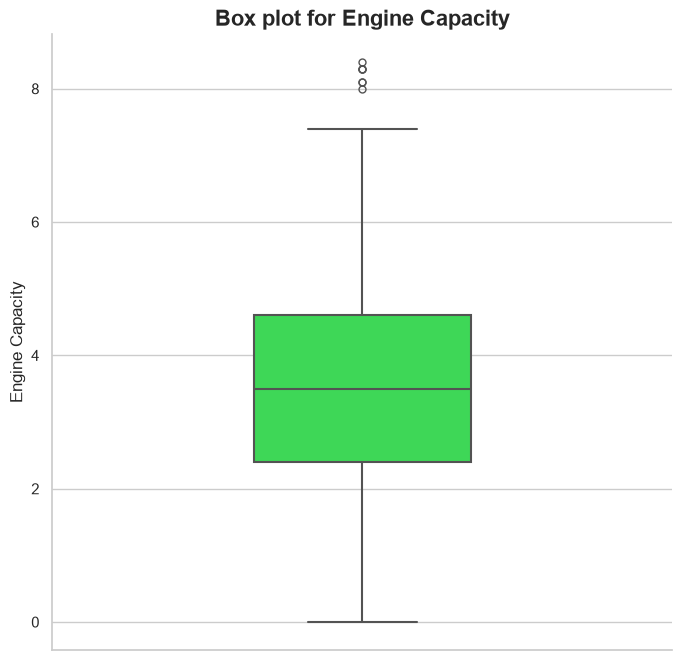

In [75]:
sns.set_theme(style='whitegrid')

fig,axes=plt.subplots(figsize=(8,8))

sns.boxplot(
    y=df["Engine_Capacity"],
    color="#24F146",
    width=0.35,
    linewidth=1.5,
    fliersize=5,
    ax=axes
)
axes.set_title("Box plot for Engine Capacity",fontsize=16,fontweight='bold')
axes.set_ylabel("Engine Capacity")
axes.set_xlabel("")

sns.despine()
plt.tight_layout(rect=[0,0.97,1,1])
plt.show()

In [76]:
df['Engine_Capacity']=df['Engine_Capacity'].fillna(df['Engine_Capacity'].median())

In [77]:
missing_info={}
for col in Numerical_Columns:
    if df[col].isnull().sum()>0:
        missing_count=(df[col].isnull().sum()/len(df))*100
        missing_info[col]=round(missing_count,2)
print("\n The Numerical columns with missing percentage is:\n")
for col,per in missing_info.items():
    print(f"{col}: {per}%")
    


 The Numerical columns with missing percentage is:

Horse_Power: 20.15%


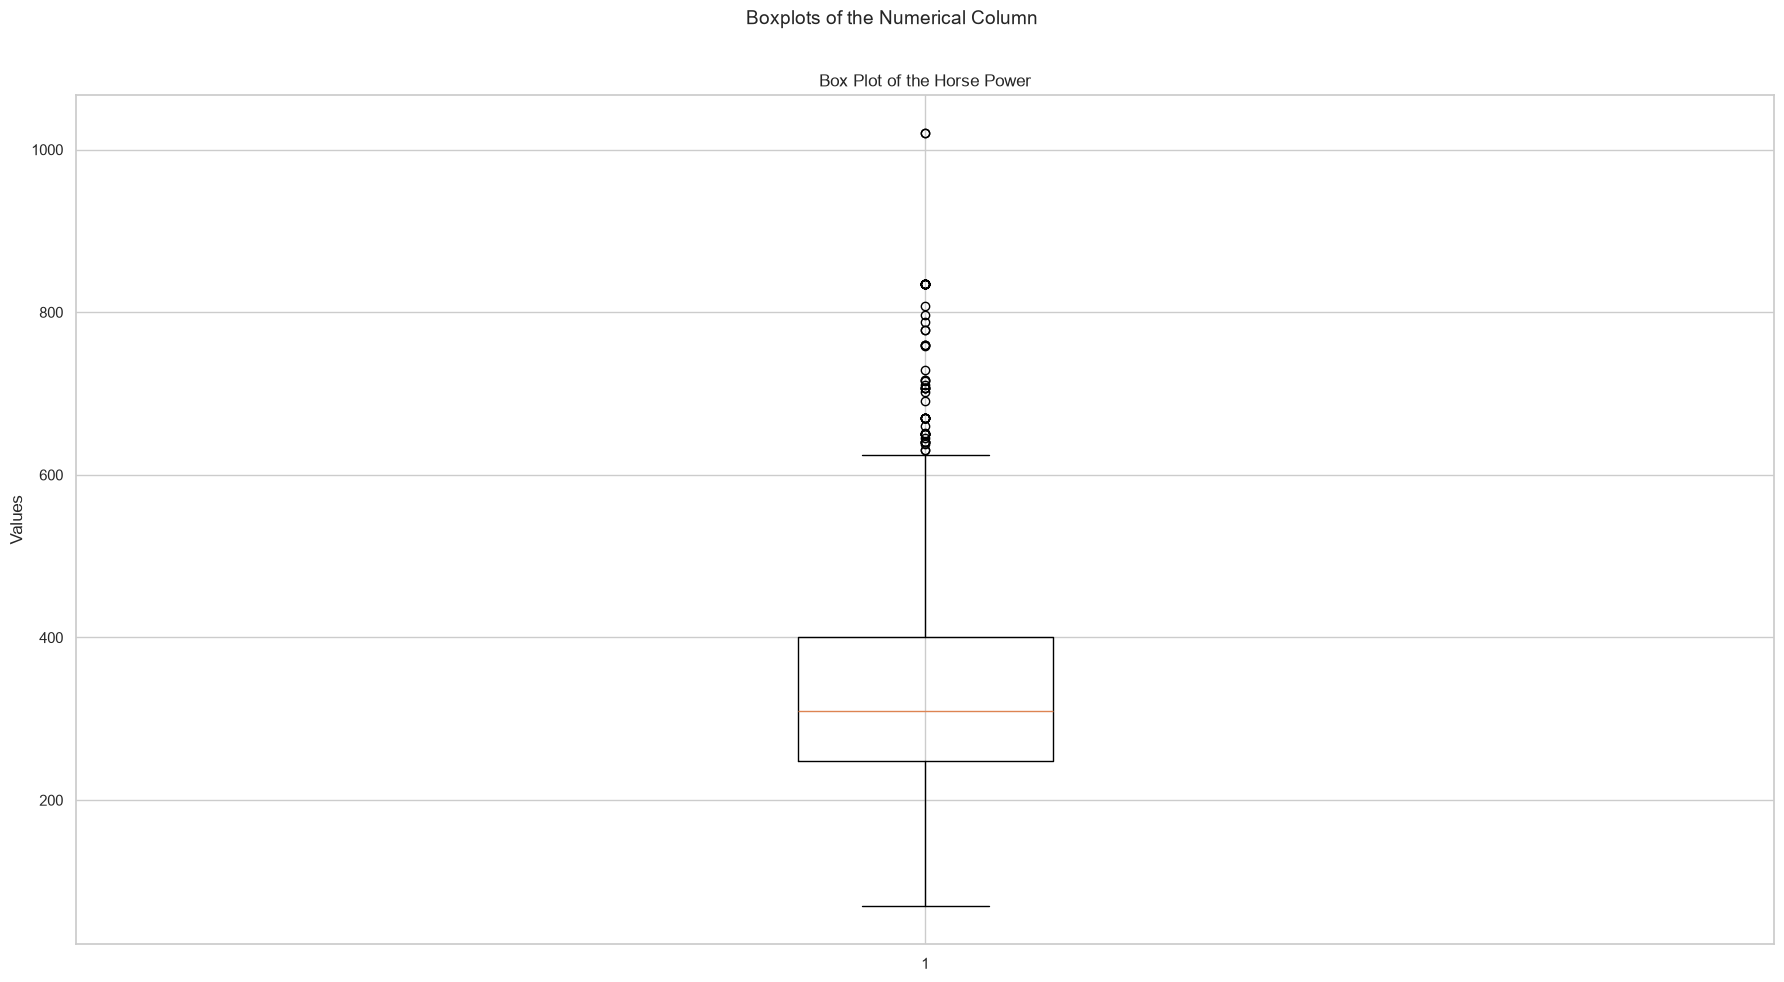

In [78]:
fig, axes = plt.subplots(figsize=(18,10))
axes.boxplot(df['Horse_Power'].dropna())
axes.set_title("Box Plot of the Horse Power")
axes.set_ylabel("Values")
plt.suptitle("Boxplots of the Numerical Column",fontsize=14)
plt.tight_layout(rect=[0,0,1,0.97])
plt.show()

In [79]:
skew_value=df['Horse_Power'].skew()
print(f'The skewness of the Horse Power is : {skew_value:.3f}')

The skewness of the Horse Power is : 0.947


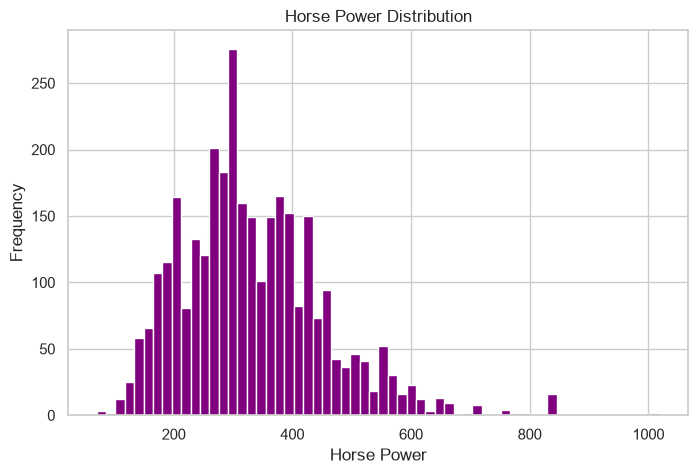

In [80]:
fig, axes = plt.subplots(figsize=(8,5))
axes.hist(df['Horse_Power'].dropna(),bins=60,color='purple')
axes.set_title("Horse Power Distribution")
axes.set_xlabel("Horse Power")
axes.set_ylabel("Frequency")
plt.show()

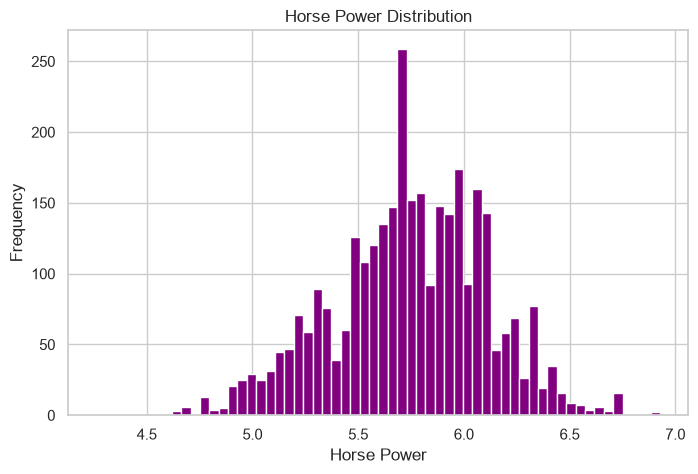

In [81]:
fig, axes = plt.subplots(figsize=(8,5))
axes.hist(np.log1p(df['Horse_Power']).dropna(),bins=60,color='purple')
axes.set_title("Horse Power Distribution")
axes.set_xlabel("Horse Power")
axes.set_ylabel("Frequency")
plt.show()

In [82]:
numeric_cols = ['Engine_Capacity','model_year','milage','Horse_Power','price']
df[numeric_cols]=df[numeric_cols].apply(pd.to_numeric,errors='coerce')

known=df[df['Horse_Power'].notna()]
missing=df[df['Horse_Power'].isna()]

numerical_features=['Engine_Capacity','model_year','milage','price']
categorical_features=['brand']

preprocessor=ColumnTransformer(
    transformers=[
('cat',OneHotEncoder(handle_unknown='ignore'),categorical_features)
    ],
remainder='passthrough'
)

pipeline=Pipeline(steps=[
    ('preprocessors',preprocessor),

    ('regressor',LinearRegression())
])


pipeline.fit(
    known[categorical_features+numerical_features],
    known['Horse_Power']
)

predicted_horsepower=pipeline.predict(missing[categorical_features+numerical_features])

df.loc[df['Horse_Power'].isna(),'Horse_Power']=predicted_horsepower

df['Horse_Power']=df['Horse_Power'].clip(lower=0)

print("All the missing values are filled with the linear regression imputation technique.")

All the missing values are filled with the linear regression imputation technique.


In [83]:
df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,Accident_Occurred,Engine_Capacity,Horse_Power
0,Ford,Utility Police Interceptor Base,2013,51000.0,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capability,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300.0,YES,3.7,300.000000
1,Hyundai,Palisade SEL,2021,34742.0,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005.0,YES,3.8,386.175639
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,Unknown,54598.0,NO,3.5,392.374551
3,INFINITI,Q50 Hybrid Sport,2015,88900.0,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric Hybrid,7-Speed A/T,Black,Black,None reported,Yes,15500.0,NO,3.5,354.000000
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,Unknown,34999.0,NO,2.0,334.254113


In [84]:
missing_info={}
for col in Numerical_Columns:
    if df[col].isnull().sum()>0:
        missing_count=(df[col].isnull().sum()/len(df))*100
        missing_info[col]=round(missing_count,2)
print("\n The Numerical columns with missing percentage is:\n")
for col,per in missing_info.items():
    print(f"{col}: {per}%")


 The Numerical columns with missing percentage is:



In [85]:
missing_info={}
for col in Categorical_Columns:
    if df[col].isnull().sum()>0:
        missing_count=(df[col].isnull().sum()/len(df))*100
        missing_info[col]=round(missing_count,2)
print("\n The Categorical columns with missing percentage is:\n")
for col,per in missing_info.items():
    print(f"{col}: {per}%")


 The Categorical columns with missing percentage is:



### Handling Duplicate Values


In [86]:
df.duplicated().sum()

np.int64(0)

### Outlier Detection

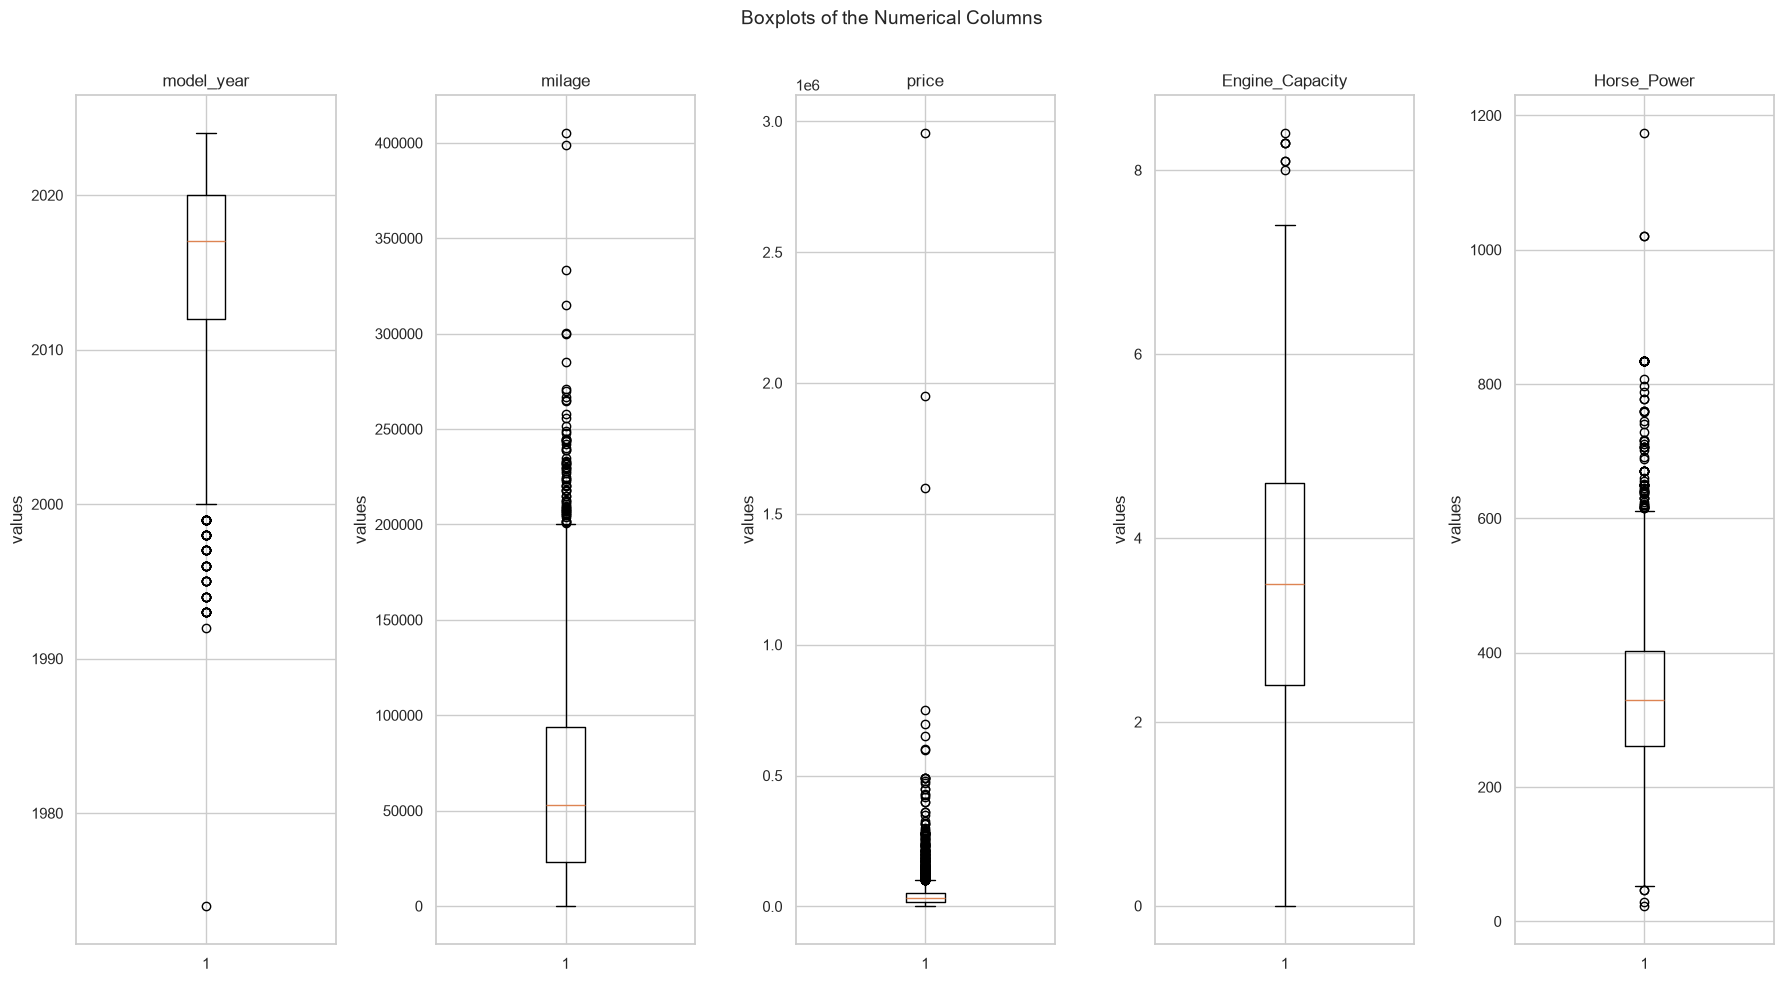

In [87]:
fig,axes = plt.subplots(1,5,figsize=(18,10))

for i, cols in enumerate(Numerical_Columns):
    axes[i].boxplot(df[cols].dropna())
    axes[i].set_title(cols)
    axes[i].set_ylabel("values")

plt.suptitle("Boxplots of the Numerical Columns", fontsize=14)
plt.tight_layout(rect=[0,0,1,0.97])
plt.show()

## Procedure to remove outliers from the Numerical Columns (if necessary)

### Histogram with kde and Q-Q plots

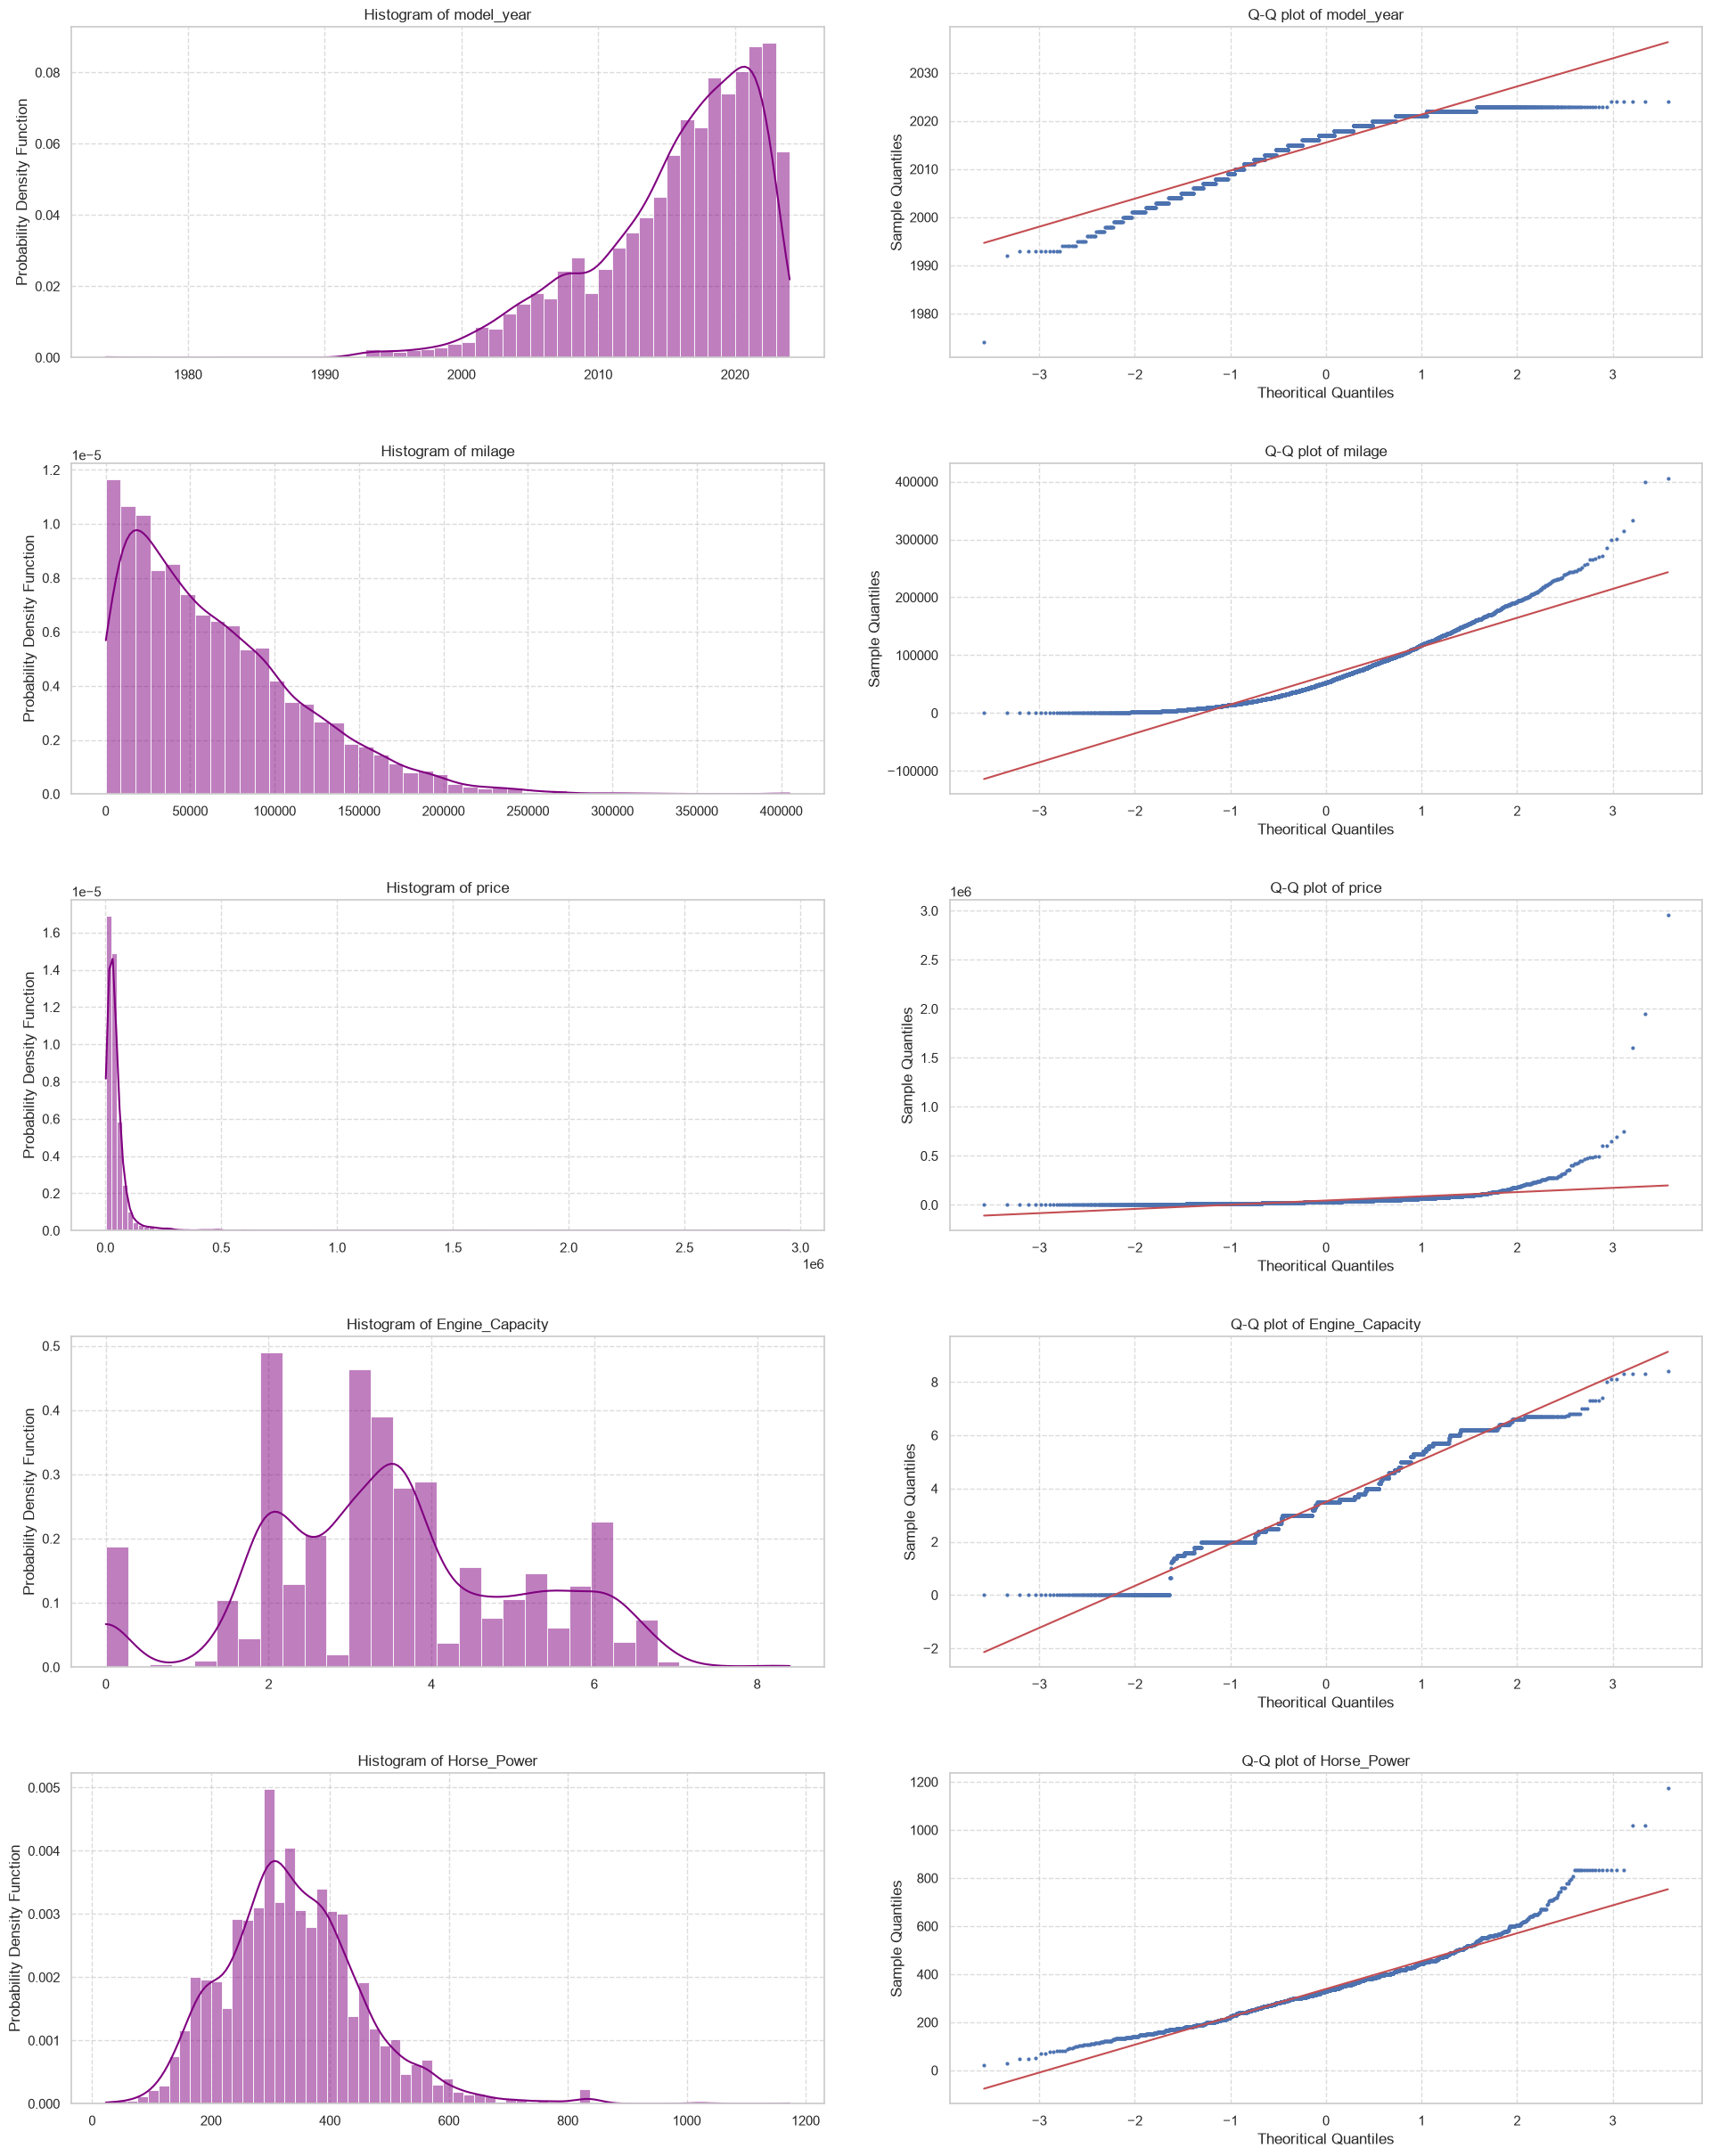

In [88]:
import scipy.stats as stats

num_cols=len(Numerical_Columns)
fig,axes=plt.subplots(num_cols,2,figsize=(20,num_cols*5))

for i, cols in enumerate(Numerical_Columns):
    sns.histplot(df[cols],kde=True,color='purple',ax=axes[i,0],stat='density',linewidth=0.6)
    axes[i,0].set_title(f'Histogram of {cols}')
    axes[i,0].set_xlabel('')
    axes[i,0].set_ylabel('Probability Density Function')
    axes[i,0].grid(True,linestyle='--',alpha=0.7)

    stats.probplot(df[cols],plot=axes[i,1],dist='norm',fit=True)
    axes[i,1].set_title(f'Q-Q plot of {cols}')
    axes[i,1].set_xlabel('Theoritical Quantiles')
    axes[i,1].set_ylabel('Sample Quantiles')
    axes[i,1].grid(True, linestyle='--', alpha=0.7)
    axes[i,1].get_lines()[0].set_markersize(2.0)

plt.tight_layout(pad=3.0)
plt.show()

### Strong Evidence to Statistical Test

In [89]:
def testing_Normality(df,col):
    print("="*70)
    print(f'Normality tests for columns: **{col}**')
    print('-'*70)

    #Shapiro-wilk Test
    stat,p=shapiro(df[col])
    print(f"Shapiro-wilk test :stat={stat:.4f} ,p={p:.4f} -> {'Normal' if p>0.05 else 'Not-Normal'}")

    #Anderson-Darling Test
    value=anderson(df[col])
    critical_value=value.critical_values[2]
    print(f"Anderson Darling Test : stat={value.statistic:.4f}, critical_value={critical_value:.4f} -> {'Normal' if value.statistic<critical_value else 'Not-Normal'}")

    #Jarque-bera test
    jb_stats,jb_p = jarque_bera(df[col])
    print(f"jarque_bera test : stat= {jb_stats:.4f}, p={jb_p:.4f} -> {'Normal' if p>0.05 else 'Not-Normal'}")

    # D-Agostino's and persons test
    d_stat,d_p=shapiro(df[col])
    print(f"D-Agostino's and persons test :stat={d_stat:.4f} ,p={d_p:.4f} -> {'Normal' if p>0.05 else 'Not-Normal'}")

    print("\n")

for col in Numerical_Columns:
    testing_Normality(df,col)
    

Normality tests for columns: **model_year**
----------------------------------------------------------------------
Shapiro-wilk test :stat=0.9090 ,p=0.0000 -> Not-Normal
Anderson Darling Test : stat=102.2070, critical_value=0.7520 -> Not-Normal
jarque_bera test : stat= 993.7930, p=0.0000 -> Not-Normal
D-Agostino's and persons test :stat=0.9090 ,p=0.0000 -> Not-Normal


Normality tests for columns: **milage**
----------------------------------------------------------------------
Shapiro-wilk test :stat=0.9105 ,p=0.0000 -> Not-Normal
Anderson Darling Test : stat=85.9013, critical_value=0.7520 -> Not-Normal
jarque_bera test : stat= 1407.6247, p=0.0000 -> Not-Normal
D-Agostino's and persons test :stat=0.9105 ,p=0.0000 -> Not-Normal


Normality tests for columns: **price**
----------------------------------------------------------------------
Shapiro-wilk test :stat=0.2999 ,p=0.0000 -> Not-Normal
Anderson Darling Test : stat=614.1549, critical_value=0.7520 -> Not-Normal
jarque_bera test : s

C:\Users\user\AppData\Local\Temp\ipykernel_14024\1995586444.py:11: FutureWarning: As of SciPy 1.17, users must choose a p-value calculation method by providing the `method` parameter. `method='interpolate'` interpolates the p-value from pre-calculated tables; `method` may also be an instance of `MonteCarloMethod` to approximate the p-value via Monte Carlo simulation. When `method` is specified, the result object will include a `pvalue` attribute and not attributes `critical_value`, `significance_level`, or `fit_result`. Beginning in 1.19.0, these other attributes will no longer be available, and a p-value will always be computed according to one of the available `method` options.
  value=anderson(df[col])


### Removing an Outliers (if necessary)

Function to detetct outliers using IQR method

In [94]:
def detect_outliers_using_iqr(data):
    outlier_mask=pd.Series(index= data.columns,dtype=bool)

    for col in data.columns:
        if col in Numerical_Columns:
            Q1=data[col].quantile(0.25)
            Q3=data[col].quantile(0.75)
            IQR=Q3-Q1
            lower_bound=Q1-1.5*IQR
            upper_bound=Q3-1.5*IQR
            col_outlier_mask=(
                (data[col]<lower_bound) | (data[col]>upper_bound)
            )
            outlier_mask[col]=col_outlier_mask.any()
    return outlier_mask
outliers_iqr_mask=detect_outliers_using_iqr(df)
print("\nOutliers detected using IQR is:\n")
for col,is_outlier in outliers_iqr_mask.items():
    print(f'{col} : {is_outlier}')


Outliers detected using IQR is:

brand : True
model : True
model_year : True
milage : True
fuel_type : True
engine : True
transmission : True
ext_col : True
int_col : True
accident : True
clean_title : True
price : True
Accident_Occurred : True
Engine_Capacity : True
Horse_Power : True


Function to detect outliers using Z-score method

In [97]:
def detect_outliers_using_zscore(data,threshold=3):
    outlier_mask = pd.Series(index=data.columns,dtype=bool)

    for col in data.columns:
        if col in Numerical_Columns:
            mean=np.mean(data[col])
            std_deviation=np.std(data[col])
            z_scores=np.abs((data[col]-mean)/std_deviation)
            col_outliers_mask=z_scores>threshold
            outlier_mask[col]=col_outliers_mask.any()
    return outlier_mask
outliers_zscore_mask=detect_outliers_using_zscore(df)
print("\nOutliers detected using z-score is :\n")
for col, is_outlier in outliers_zscore_mask.items():
    print(f'{col} : {is_outlier}')


Outliers detected using z-score is :

brand : True
model : True
model_year : True
milage : True
fuel_type : True
engine : True
transmission : True
ext_col : True
int_col : True
accident : True
clean_title : True
price : True
Accident_Occurred : True
Engine_Capacity : True
Horse_Power : True
